<a href="https://colab.research.google.com/github/HeliosSkotis/HeliosSkotis.github.io/blob/main/GNN_FraudDetection.ipynb" target="_parent"><img src="https://colab.research.google.com/assets/colab-badge.svg" alt="Open In Colab"/></a>

In [ ]:

import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns

from sklearn.model_selection import train_test_split
from sklearn.preprocessing import StandardScaler
from google.colab import files

print("Libraries imported successfully")


Libraries imported successfully


In [ ]:
# ============================================================
# 1. DATA LOADING
# ============================================================

# import pandas as pd
# import numpy as np

# train_transaction = pd.read_csv("/content/sample_data/train_transaction.csv")
# train_identity = pd.read_csv("/content/sample_data/train_identity.csv")

# test_transaction = pd.read_csv("/content/sample_data/test_transaction.csv")
# test_identity = pd.read_csv("/content/sample_data/test_identity.csv")

# print("Train Transaction Shape:", train_transaction.shape)
# print("Train Identity Shape:", train_identity.shape)
# print("Test Transaction Shape:", test_transaction.shape)
# print("Test Identity Shape:", test_identity.shape)
# print("All 4 files loaded successfully!")

In [ ]:
from google.colab import files
import zipfile
import os

# Upload your ZIP file
uploaded = files.upload()

zip_name = next(iter(uploaded.keys()))

# Extract ZIP file
extract_path = "/content/fraud_data"
os.makedirs(extract_path, exist_ok=True)

with zipfile.ZipFile(zip_name, "r") as zip_ref:
    zip_ref.extractall(extract_path)

print("ZIP file extracted successfully!")

Saving archive.zip to archive (1).zip
ZIP file extracted successfully!


In [ ]:
import pandas as pd
import os

def find_csv(filename):
    for root, dirs, files_list in os.walk("/content/fraud_data"):
        if filename in files_list:
            return os.path.join(root, filename)
    raise FileNotFoundError(f"{filename} not found in ZIP file")

train_transaction = pd.read_csv(
    find_csv("train_transaction.csv"), low_memory=False
)
print("Train transaction:", train_transaction.shape)

train_identity = pd.read_csv(
    find_csv("train_identity.csv"), low_memory=False
)
print("Train identity:", train_identity.shape)

test_transaction = pd.read_csv(
    find_csv("test_transaction.csv"), low_memory=False
)
print("Test transaction:", test_transaction.shape)

test_identity = pd.read_csv(
    find_csv("test_identity.csv"), low_memory=False
)
print("Test identity:", test_identity.shape)

print("All four CSV files loaded successfully!")

Train transaction: (590540, 394)
Train identity: (144233, 41)
Test transaction: (506691, 393)
Test identity: (141907, 41)
All four CSV files loaded successfully!


In [ ]:
# ============================================================
# 1.1 MERGE DATASETS
# ============================================================

# train = train_transaction.merge(
#     train_identity,
#     on="TransactionID",
#     how="left"
# )

# test = test_transaction.merge(
#     test_identity,
#     on="TransactionID",
#     how="left"
# )

# print("Merged Train Shape:", train.shape)
# print("Merged Test Shape:", test.shape)

# display(train.head())

train = train_transaction.merge(
    train_identity, on="TransactionID", how="left"
)

test = test_transaction.merge(
    test_identity, on="TransactionID", how="left"
)

print("Train shape:", train.shape)
print("Test shape:", test.shape)
print("Fraud target available:", "isFraud" in train.columns)

Train shape: (590540, 434)
Test shape: (506691, 433)
Fraud target available: True


In [ ]:
# ============================================================
# 2. EXPLORATORY DATA ANALYSIS
# ============================================================

print("Dataset Shape:")
print(train.shape)

print("\nColumns:")
print(train.columns.tolist())

print("\nData Types:")
print(train.dtypes.head(30))

print("\nFirst 5 Rows:")
display(train.head())

print("\nMissing Values:")
missing = train.isnull().sum().sort_values(
    ascending=False
)

display(missing.head(30))

Dataset Shape:
(590540, 434)

Columns:
['TransactionID', 'isFraud', 'TransactionDT', 'TransactionAmt', 'ProductCD', 'card1', 'card2', 'card3', 'card4', 'card5', 'card6', 'addr1', 'addr2', 'dist1', 'dist2', 'P_emaildomain', 'R_emaildomain', 'C1', 'C2', 'C3', 'C4', 'C5', 'C6', 'C7', 'C8', 'C9', 'C10', 'C11', 'C12', 'C13', 'C14', 'D1', 'D2', 'D3', 'D4', 'D5', 'D6', 'D7', 'D8', 'D9', 'D10', 'D11', 'D12', 'D13', 'D14', 'D15', 'M1', 'M2', 'M3', 'M4', 'M5', 'M6', 'M7', 'M8', 'M9', 'V1', 'V2', 'V3', 'V4', 'V5', 'V6', 'V7', 'V8', 'V9', 'V10', 'V11', 'V12', 'V13', 'V14', 'V15', 'V16', 'V17', 'V18', 'V19', 'V20', 'V21', 'V22', 'V23', 'V24', 'V25', 'V26', 'V27', 'V28', 'V29', 'V30', 'V31', 'V32', 'V33', 'V34', 'V35', 'V36', 'V37', 'V38', 'V39', 'V40', 'V41', 'V42', 'V43', 'V44', 'V45', 'V46', 'V47', 'V48', 'V49', 'V50', 'V51', 'V52', 'V53', 'V54', 'V55', 'V56', 'V57', 'V58', 'V59', 'V60', 'V61', 'V62', 'V63', 'V64', 'V65', 'V66', 'V67', 'V68', 'V69', 'V70', 'V71', 'V72', 'V73', 'V74', 'V75', 'V76'

,TransactionID,isFraud,TransactionDT,TransactionAmt,ProductCD,card1,card2,card3,card4,card5,...,id_31,id_32,id_33,id_34,id_35,id_36,id_37,id_38,DeviceType,DeviceInfo
0,2987000,0,86400,68.5,W,13926,NaN,150.0,discover,142.0,...,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN
1,2987001,0,86401,29.0,W,2755,404.0,150.0,mastercard,102.0,...,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN
2,2987002,0,86469,59.0,W,4663,490.0,150.0,visa,166.0,...,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN
3,2987003,0,86499,50.0,W,18132,567.0,150.0,mastercard,117.0,...,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN
4,2987004,0,86506,50.0,H,4497,514.0,150.0,mastercard,102.0,...,samsung browser 6.2,32.0,2220x1080,match_status:2,T,F,T,T,mobile,SAMSUNG SM-G892A Build/NRD90M



Missing Values:


,0
id_24,585793
id_25,585408
id_07,585385
id_08,585385
id_21,585381
id_26,585377
id_27,585371
id_23,585371
id_22,585371
dist2,552913


Fraud Distribution:
isFraud
0    569877
1     20663
Name: count, dtype: int64

Fraud Percentage:
isFraud
0    96.500999
1     3.499001
Name: proportion, dtype: float64
isFraud present: True

Fraud Distribution:
isFraud
0    569877
1     20663
Name: count, dtype: int64

Fraud Percentage:
isFraud
0    96.500999
1     3.499001
Name: proportion, dtype: float64


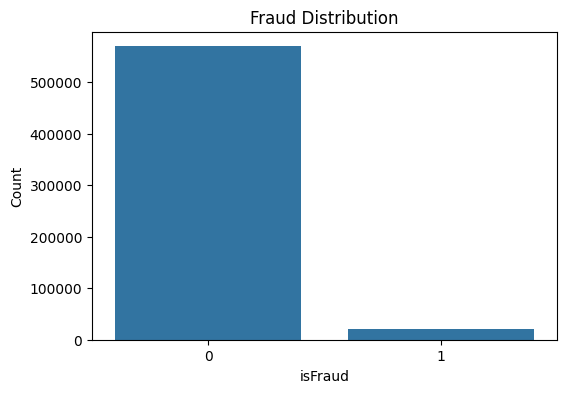

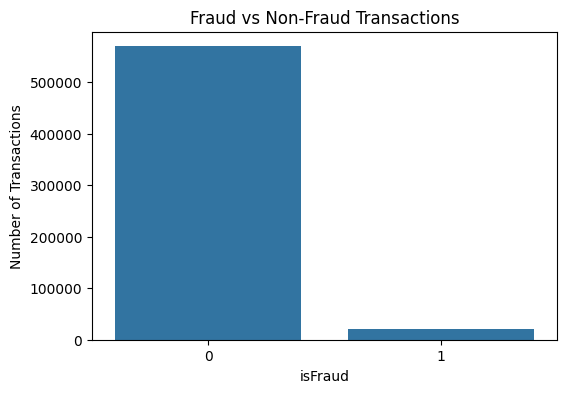

In [ ]:
# ============================================================
# 2.1 FRAUD DISTRIBUTION
# ============================================================
import matplotlib.pyplot as plt
import seaborn as sns

plt.figure(figsize=(6,4))

sns.countplot(
    x="isFraud",
    data=train
)

plt.title("Fraud Distribution")
plt.xlabel("isFraud")
plt.ylabel("Count")

print("Fraud Distribution:")
print(train["isFraud"].value_counts())

print("\nFraud Percentage:")
print(
    train["isFraud"]
    .value_counts(normalize=True) * 100
)

plt.figure(figsize=(6,4))

sns.countplot(
    x="isFraud",
    data=train
)
print("isFraud present:",
      "isFraud" in train.columns)

print("\nFraud Distribution:")
print(train["isFraud"].value_counts())

print("\nFraud Percentage:")
print(train["isFraud"].value_counts(normalize=True) * 100)

plt.title("Fraud vs Non-Fraud Transactions")
plt.xlabel("isFraud")
plt.ylabel("Number of Transactions")

plt.show()

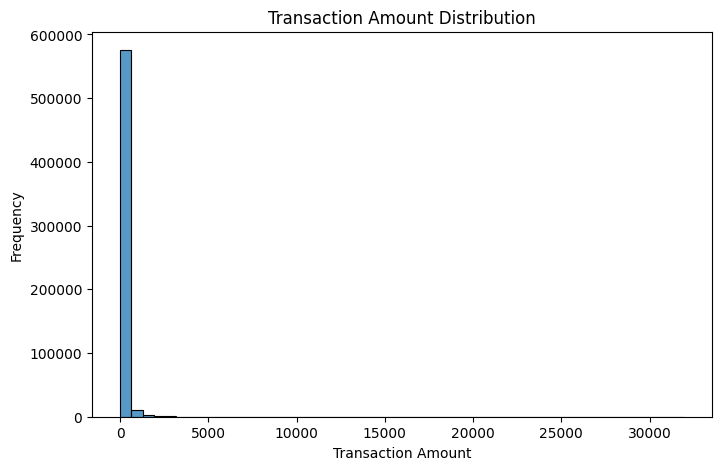

In [ ]:
# ============================================================
# 2.2 TRANSACTION AMOUNT DISTRIBUTION
# ============================================================

plt.figure(figsize=(8,5))

sns.histplot(
    train["TransactionAmt"],
    bins=50
)

plt.title("Transaction Amount Distribution")
plt.xlabel("Transaction Amount")
plt.ylabel("Frequency")

plt.show()

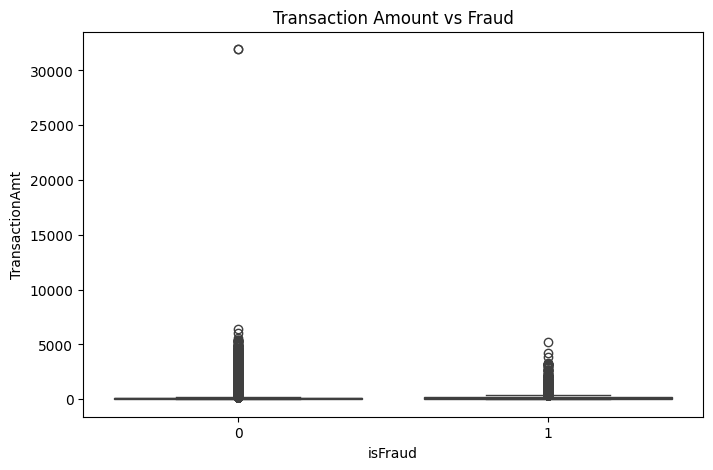

In [ ]:
# ============================================================
# 2.3 TRANSACTION AMOUNT VS FRAUD
# ============================================================
import matplotlib.pyplot as plt
import seaborn as sns

plt.figure(figsize=(8,5))

sns.boxplot(
    x="isFraud",
    y="TransactionAmt",
    data=train
)

plt.title("Transaction Amount vs Fraud")
plt.show()

In [ ]:
features = [
    "TransactionDT",
    "TransactionAmt",
    "card1",
    "card2",
    "card3",
    "card5",
    "addr1",
    "addr2",
    "dist1",
    "dist2"
]

features += [f"C{i}" for i in range(1, 15)]

features += [f"D{i}" for i in range(1, 16)]

features += [f"V{i}" for i in range(1, 31)]

features = [
    col for col in features
    if col in train.columns
]

print("Number of features:", len(features))
print(features)

Number of features: 69
['TransactionDT', 'TransactionAmt', 'card1', 'card2', 'card3', 'card5', 'addr1', 'addr2', 'dist1', 'dist2', 'C1', 'C2', 'C3', 'C4', 'C5', 'C6', 'C7', 'C8', 'C9', 'C10', 'C11', 'C12', 'C13', 'C14', 'D1', 'D2', 'D3', 'D4', 'D5', 'D6', 'D7', 'D8', 'D9', 'D10', 'D11', 'D12', 'D13', 'D14', 'D15', 'V1', 'V2', 'V3', 'V4', 'V5', 'V6', 'V7', 'V8', 'V9', 'V10', 'V11', 'V12', 'V13', 'V14', 'V15', 'V16', 'V17', 'V18', 'V19', 'V20', 'V21', 'V22', 'V23', 'V24', 'V25', 'V26', 'V27', 'V28', 'V29', 'V30']


In [ ]:
# Define the feature set locally to ensure it is defined
candidate_features = [
    "TransactionDT",
    "TransactionAmt",
    "card1",
    "card2",
    "card3",
    "card5",
    "addr1",
    "addr2",
    "dist1",
    "dist2"
]
candidate_features += [f"C{i}" for i in range(1, 15)]
candidate_features += [f"D{i}" for i in range(1, 16)]
candidate_features += [f"V{i}" for i in range(1, 31)]

features = [
    col for col in candidate_features
    if col in train.columns
]

X = train[features].copy()
y = train["isFraud"].astype(int)

print("X shape:", X.shape)
print("y shape:", y.shape)

X shape: (590540, 69)
y shape: (590540,)


In [ ]:

import numpy as np

X = X.replace(
    [np.inf, -np.inf],
    np.nan
)

for col in X.columns:
    X[col] = pd.to_numeric(
        X[col],
        errors="coerce"
    )

X = X.fillna(X.median())

print("Remaining missing values:")
print(X.isnull().sum().sum())

Remaining missing values:
0


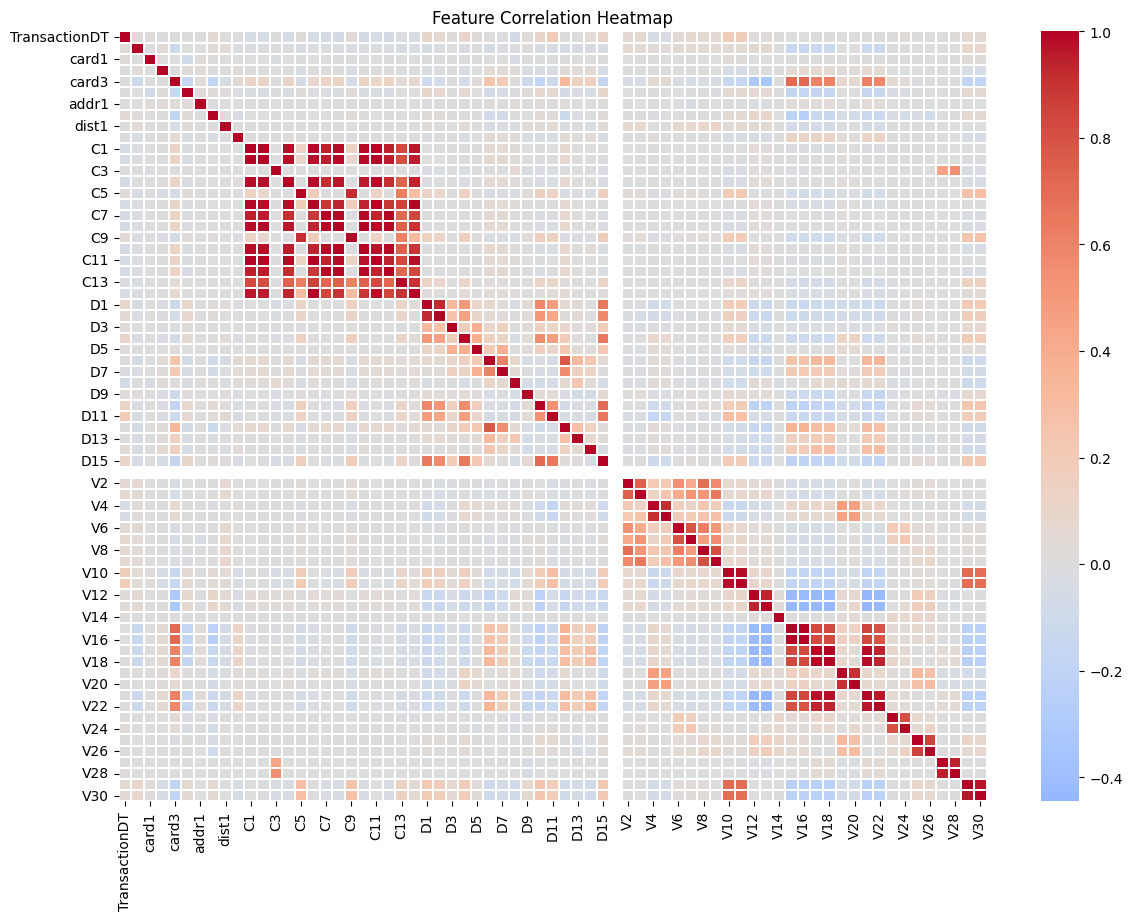

In [ ]:
# ============================================================
# 3. CORRELATION
# ============================================================

corr_sample = X.sample(
    n=min(10000, len(X)),
    random_state=42
)

corr = corr_sample.corr()

plt.figure(figsize=(14,10))

sns.heatmap(
    corr,
    cmap="coolwarm",
    center=0,
    linewidths=0.1
)

plt.title("Feature Correlation Heatmap")

plt.show()

In [ ]:
fraud_corr = pd.concat(
    [X, y],
    axis=1
).corr()["isFraud"].sort_values(
    ascending=False
)

print("Correlation with isFraud:")

display(fraud_corr.head(20))

Correlation with isFraud:


,isFraud
isFraud,1.000000
V17,0.158972
V18,0.158933
V15,0.154755
card3,0.154028
V16,0.151645
V21,0.143769
V22,0.137627
V23,0.132921
V24,0.109155


In [ ]:
from sklearn.model_selection import train_test_split
from sklearn.preprocessing import StandardScaler

X_train, X_test, y_train, y_test = train_test_split(
    X,
    y,
    test_size=0.20,
    random_state=42,
    stratify=y
)

print("Training samples:", X_train.shape)
print("Testing samples:", X_test.shape)

print("\nTraining fraud distribution:")
print(y_train.value_counts())

print("\nTesting fraud distribution:")
print(y_test.value_counts())

Training samples: (472432, 69)
Testing samples: (118108, 69)

Training fraud distribution:
isFraud
0    455902
1     16530
Name: count, dtype: int64

Testing fraud distribution:
isFraud
0    113975
1      4133
Name: count, dtype: int64


In [ ]:
#Normalization
from sklearn.model_selection import train_test_split
from sklearn.preprocessing import StandardScaler

scaler = StandardScaler()

X_train_scaled = scaler.fit_transform(X_train)

X_test_scaled = scaler.transform(X_test)

X_train_scaled = pd.DataFrame(
    X_train_scaled,
    columns=X_train.columns,
    index=X_train.index
)

X_test_scaled = pd.DataFrame(
    X_test_scaled,
    columns=X_test.columns,
    index=X_test.index
)

print("Normalization completed!")

display(X_train_scaled.head())

Normalization completed!


,TransactionDT,TransactionAmt,card1,card2,card3,card5,addr1,addr2,dist1,dist2,...,V21,V22,V23,V24,V25,V26,V27,V28,V29,V30
40809,-1.378728,-0.145302,-0.759998,0.233074,-0.28177,-1.203320,-0.288437,0.06972,-0.183973,-0.340301,...,-0.354536,-0.341658,-0.130081,-0.176413,0.112501,0.054821,-0.025424,-0.025032,-0.682538,-0.660940
285886,-0.079104,-0.435353,-0.408558,-0.111786,-0.28177,0.595819,-1.549208,0.06972,-0.200482,-0.087420,...,-0.354536,-0.341658,-0.130081,-0.176413,0.112501,0.054821,-0.025424,-0.025032,-0.682538,-0.660940
104256,-1.148460,-0.112365,0.364489,-1.606179,-0.28177,0.644444,-1.049068,0.06972,-0.183973,-0.087420,...,-0.354536,-0.341658,-0.130081,-0.176413,0.112501,0.054821,-0.025424,-0.025032,1.342589,1.210935
507860,1.283733,0.442796,-1.486336,-0.226739,-0.28177,-2.370329,0.399256,0.06972,-0.204610,-0.087420,...,-0.354536,-0.341658,-0.130081,-0.176413,0.112501,0.054821,-0.025424,-0.025032,1.342589,1.210935
196382,-0.641418,-0.074871,0.790786,-0.411942,-0.28177,0.644444,1.555830,0.06972,-0.196355,-0.087420,...,-0.354536,-0.341658,-0.130081,-0.176413,0.112501,0.054821,-0.025424,-0.025032,-0.682538,-0.660940


In [ ]:
!pip install torch-geometric

In [ ]:
import pandas as pd
import numpy as np

# Merge training transaction and identity data
train = train_transaction.merge(
    train_identity,
    on="TransactionID",
    how="left"
)

# Use a sample to avoid Colab memory errors
SAMPLE_SIZE = min(30000, len(train))
data = train.sample(n=SAMPLE_SIZE, random_state=42).copy()
data = data.reset_index(drop=True)

if "isFraud" not in data.columns:
    raise ValueError("isFraud is missing. Check train_transaction.csv.")

print("Sample shape:", data.shape)
print("Fraud counts:")
print(data["isFraud"].value_counts())

Sample shape: (30000, 434)
Fraud counts:
isFraud
0    28926
1     1074
Name: count, dtype: int64


In [ ]:
from sklearn.model_selection import train_test_split
from sklearn.preprocessing import StandardScaler

target = "isFraud"

# Select numeric features available in the dataset
candidate_features = [
    "TransactionDT", "TransactionAmt",
    "card1", "card2", "card3", "card5",
    "addr1", "addr2", "dist1", "dist2"
]

candidate_features += [f"C{i}" for i in range(1, 15)]
candidate_features += [f"D{i}" for i in range(1, 16)]
candidate_features += [f"V{i}" for i in range(1, 31)]

features = [
    col for col in candidate_features
    if col in data.columns and col != target
]

X = data[features].copy()

# Convert features to numeric
X = X.apply(pd.to_numeric, errors="coerce")
X = X.replace([np.inf, -np.inf], np.nan)

# Remove columns containing only missing values
X = X.dropna(axis=1, how="all")
features = X.columns.tolist()

# Fill missing values
X = X.fillna(X.median()).fillna(0)

y = data[target].astype("int64")

# Split indices before scaling
train_idx, test_idx = train_test_split(
    np.arange(len(data)),
    test_size=0.2,
    random_state=42,
    stratify=y
)

scaler = StandardScaler()
X_train = scaler.fit_transform(X.iloc[train_idx])
X_test = scaler.transform(X.iloc[test_idx])

# Scale all nodes using the training-fitted scaler
X_all = np.zeros((len(data), X.shape[1]), dtype=np.float32)
X_all[train_idx] = X_train
X_all[test_idx] = X_test

print("Number of features:", len(features))
print("Training rows:", len(train_idx))
print("Testing rows:", len(test_idx))

Number of features: 69
Training rows: 24000
Testing rows: 6000


In [ ]:
import torch
from torch_geometric.data import Data

# Connect consecutive transactions with the same card1
edges = []

if "card1" in data.columns:
    groups = data.groupby("card1", dropna=True).indices

    for indices in groups.values():
        indices = np.sort(indices)

        if len(indices) > 1:
            a = indices[:-1]
            b = indices[1:]

            edges.extend(zip(a, b))
            edges.extend(zip(b, a))

if len(edges) == 0:
    # Fallback: connect consecutive rows
    a = np.arange(len(data) - 1)
    b = a + 1
    edges = list(zip(a, b)) + list(zip(b, a))

edge_index = torch.tensor(
    np.asarray(edges, dtype=np.int64).T,
    dtype=torch.long
)

graph = Data(
    x=torch.tensor(X_all, dtype=torch.float32),
    edge_index=edge_index,
    y=torch.tensor(y.to_numpy(), dtype=torch.long)
)

train_mask = torch.zeros(len(data), dtype=torch.bool)
test_mask = torch.zeros(len(data), dtype=torch.bool)

train_mask[train_idx] = True
test_mask[test_idx] = True

graph.train_mask = train_mask
graph.test_mask = test_mask

print(graph)
print("Number of edges:", graph.edge_index.shape[1])

Data(x=[30000, 69], edge_index=[2, 51246], y=[30000], train_mask=[30000], test_mask=[30000])
Number of edges: 51246


In [ ]:
import torch.nn.functional as F
from torch import nn
from torch_geometric.nn import GATConv

device = torch.device(
    "cuda" if torch.cuda.is_available() else "cpu"
)

class FraudGAT(nn.Module):
    def __init__(self, input_dim):
        super().__init__()

        self.gat1 = GATConv(
            input_dim, 16, heads=2, dropout=0.2
        )
        self.gat2 = GATConv(
            32, 16, heads=2, concat=False, dropout=0.2
        )
        self.output = nn.Linear(16, 2)

    def forward(self, x, edge_index):
        x = self.gat1(x, edge_index)
        x = F.elu(x)
        x = F.dropout(x, p=0.3, training=self.training)

        x = self.gat2(x, edge_index)
        x = F.elu(x)

        return self.output(x)

model = FraudGAT(graph.num_node_features).to(device)
graph = graph.to(device)

# Handle class imbalance
counts = np.bincount(y.iloc[train_idx].to_numpy(), minlength=2)
weights = len(train_idx) / (
    2 * np.maximum(counts, 1)
)

class_weights = torch.tensor(
    weights, dtype=torch.float32, device=device
)

criterion = nn.CrossEntropyLoss(weight=class_weights)
optimizer = torch.optim.Adam(
    model.parameters(), lr=0.001, weight_decay=5e-4
)

print("Device:", device)
print("Model created successfully!")

Device: cpu
Model created successfully!


In [ ]:
EPOCHS = 10

for epoch in range(EPOCHS):
    model.train()
    optimizer.zero_grad()

    logits = model(graph.x, graph.edge_index)

    loss = criterion(
        logits[graph.train_mask],
        graph.y[graph.train_mask]
    )

    loss.backward()
    optimizer.step()

    print(
        f"Epoch {epoch + 1}/{EPOCHS} | "
        f"Loss: {loss.item():.4f}"
    )

print("Training completed!")

Epoch 1/10 | Loss: 0.7026
Epoch 2/10 | Loss: 0.7021
Epoch 3/10 | Loss: 0.6918
Epoch 4/10 | Loss: 0.6830
Epoch 5/10 | Loss: 0.6781
Epoch 6/10 | Loss: 0.6749
Epoch 7/10 | Loss: 0.6733
Epoch 8/10 | Loss: 0.6645
Epoch 9/10 | Loss: 0.6627
Epoch 10/10 | Loss: 0.6617
Training completed!


In [ ]:
from sklearn.metrics import (
    accuracy_score,
    precision_score,
    recall_score,
    f1_score,
    classification_report,
    confusion_matrix
)

model.eval()

with torch.no_grad():
    logits = model(graph.x, graph.edge_index)
    predictions = logits[graph.test_mask].argmax(dim=1).cpu().numpy()
    actual = graph.y[graph.test_mask].cpu().numpy()

print("Accuracy:", accuracy_score(actual, predictions))
print("Precision:", precision_score(actual, predictions, zero_division=0))
print("Recall:", recall_score(actual, predictions, zero_division=0))
print("F1 Score:", f1_score(actual, predictions, zero_division=0))

print("\nClassification Report:")
print(classification_report(actual, predictions, zero_division=0))

print("Confusion Matrix:")
print(confusion_matrix(actual, predictions))

Accuracy: 0.5403333333333333
Precision: 0.05118249205788916
Recall: 0.6744186046511628
F1 Score: 0.09514435695538058

Classification Report:
              precision    recall  f1-score   support

           0       0.98      0.54      0.69      5785
           1       0.05      0.67      0.10       215

    accuracy                           0.54      6000
   macro avg       0.51      0.60      0.39      6000
weighted avg       0.94      0.54      0.67      6000

Confusion Matrix:
[[3097 2688]
 [  70  145]]


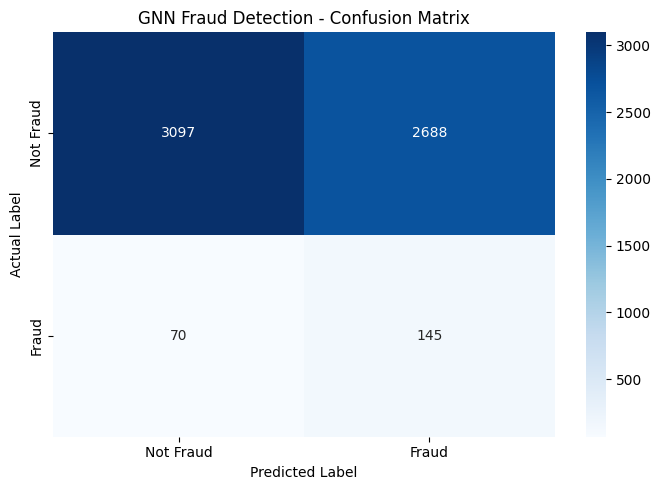

In [ ]:
import matplotlib.pyplot as plt
import seaborn as sns
from sklearn.metrics import confusion_matrix

# Calculate confusion matrix
cm = confusion_matrix(actual, predictions)

# Plot confusion matrix
plt.figure(figsize=(7, 5))
sns.heatmap(
    cm,
    annot=True,
    fmt="d",
    cmap="Blues",
    xticklabels=["Not Fraud", "Fraud"],
    yticklabels=["Not Fraud", "Fraud"]
)

plt.title("GNN Fraud Detection - Confusion Matrix")
plt.xlabel("Predicted Label")
plt.ylabel("Actual Label")
plt.tight_layout()
plt.show()